# Hydrodynamic modes: shear and sound modes

## Shear and sound modes in a static representation

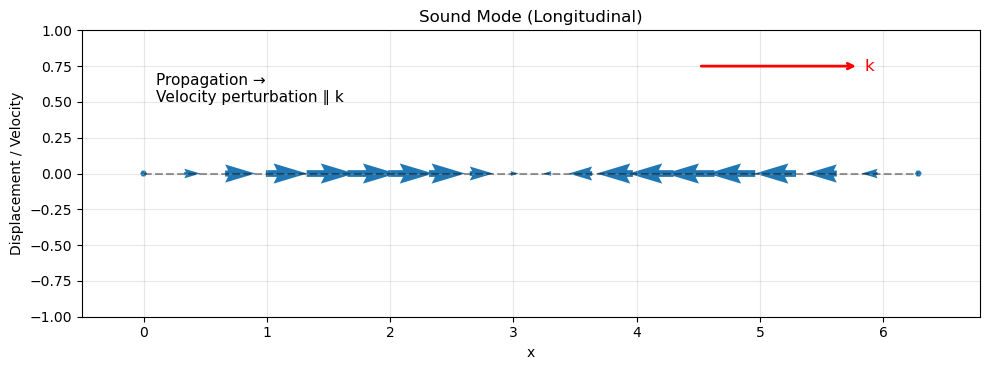

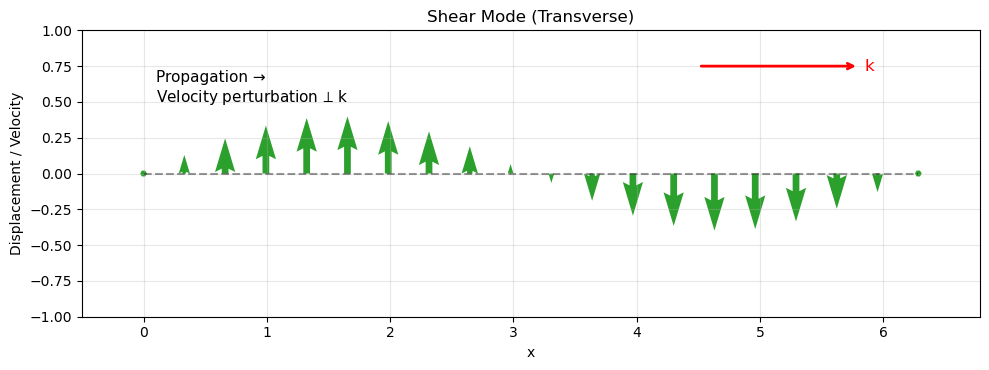

Saved:
 - sound_mode.png
 - shear_mode.png


In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Create x positions
x = np.linspace(0, 2*np.pi, 20)

# ============================================================
# 1. Sound mode (longitudinal)
# ============================================================
fig1, ax = plt.subplots(figsize=(10, 4))
#fig1.suptitle("Hydrodynamic Mode: Sound", fontsize=16)

y0 = np.zeros_like(x)
u_sound = 0.4 * np.sin(x)   # displacement/velocity along x

ax.quiver(
    x, y0,
    u_sound, np.zeros_like(x),
    angles='xy', scale_units='xy', scale=1,
    color='tab:blue'
)

ax.plot(x, y0, 'k--', alpha=0.4)
ax.set_title("Sound Mode (Longitudinal)")
ax.text(0.1, 0.5, "Propagation →\nVelocity perturbation ∥ k", fontsize=11)
ax.set_xlim(-0.5, 2*np.pi + 0.5)
ax.set_ylim(-1, 1)
ax.set_xlabel("x")
ax.set_ylabel("Displacement / Velocity")
ax.grid(True, alpha=0.3)

# Wave propagation arrow
ax.annotate(
    '', xy=(5.8, 0.75), xytext=(4.5, 0.75),
    arrowprops=dict(arrowstyle='->', lw=2, color='red')
)
ax.text(5.85, 0.75, "k", color='red', va='center', fontsize=12)

fig1.tight_layout(rect=[0, 0, 1, 0.95])
fig1.savefig("sound_mode.png", dpi=300, bbox_inches="tight")


# ============================================================
# 2. Shear mode (transverse)
# ============================================================
fig2, ax = plt.subplots(figsize=(10, 4))
#fig2.suptitle("Hydrodynamic Mode: Shear", fontsize=16)

y_base = np.zeros_like(x)
u_shear_y = 0.4 * np.sin(x)   # displacement/velocity along y

ax.quiver(
    x, y_base,
    np.zeros_like(x), u_shear_y,
    angles='xy', scale_units='xy', scale=1,
    color='tab:green'
)

ax.plot(x, y_base, 'k--', alpha=0.4)
ax.set_title("Shear Mode (Transverse)")
ax.text(0.1, 0.5, "Propagation →\nVelocity perturbation $⟂$ k", fontsize=11)
ax.set_xlim(-0.5, 2*np.pi + 0.5)
ax.set_ylim(-1, 1)
ax.set_xlabel("x")
ax.set_ylabel("Displacement / Velocity")
ax.grid(True, alpha=0.3)

# Wave propagation arrow
ax.annotate(
    '', xy=(5.8, 0.75), xytext=(4.5, 0.75),
    arrowprops=dict(arrowstyle='->', lw=2, color='red')
)
ax.text(5.85, 0.75, "k", color='red', va='center', fontsize=12)

fig2.tight_layout(rect=[0, 0, 1, 0.95])
fig2.savefig("shear_mode.png", dpi=300, bbox_inches="tight")

plt.show()

print("Saved:")
print(" - sound_mode.png")
print(" - shear_mode.png")

## Shear and sound modes caught in two different times to see their time behaviors

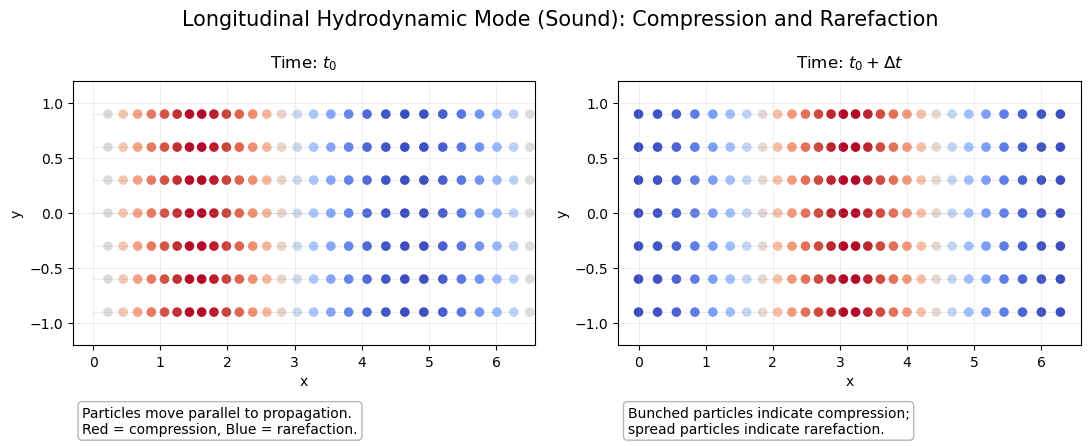

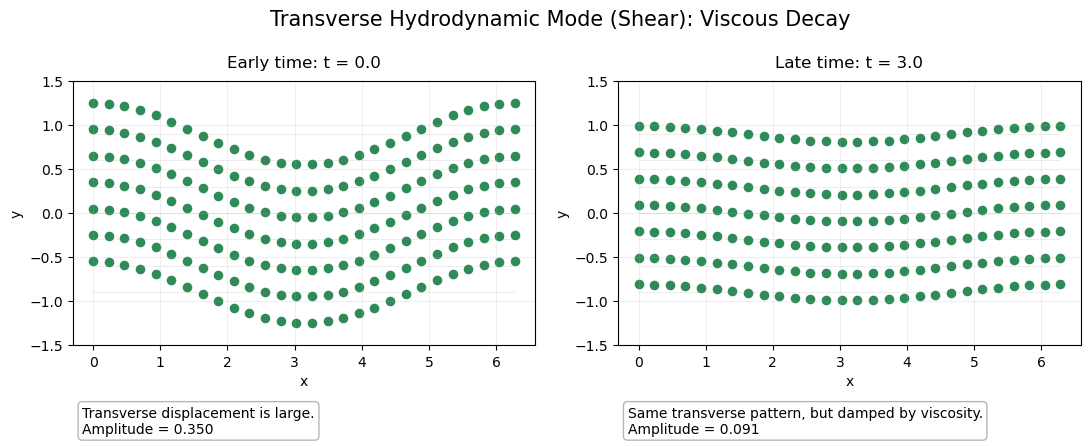

Saved:
 - longitudinal_mode.png
 - transverse_mode.png


In [18]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Parameters
# ============================================================
Lx = 2 * np.pi
Nx = 28
Ny = 7

x0 = np.linspace(0, Lx, Nx)
y0 = np.linspace(-0.9, 0.9, Ny)
X0, Y0 = np.meshgrid(x0, y0)

# Longitudinal / sound mode
A_sound = 0.22
k_sound = 1.0
omega_sound = 1.0

t_sound_1 = 0.0
t_sound_2 = np.pi / (2 * omega_sound)

# Transverse / shear mode
A_shear = 0.35
k_shear = 1.0
gamma_shear = 0.45

t_shear_1 = 0.0
t_shear_2 = 3.0

# ============================================================
# Physics definitions
# ============================================================
def sound_snapshot(t):
    phase = k_sound * X0 - omega_sound * t
    xi_x = A_sound * np.cos(phase)

    X = X0 + xi_x
    Y = Y0.copy()

    # density-like fluctuation for compression/rarefaction
    drho = k_sound * A_sound * np.sin(phase)
    return X, Y, drho


def shear_snapshot(t):
    amp = A_shear * np.exp(-gamma_shear * t)
    xi_y = amp * np.cos(k_shear * X0)

    X = X0.copy()
    Y = Y0 + xi_y
    return X, Y, amp


# ============================================================
# Plot helpers
# ============================================================
def draw_background_lines(ax):
    for yy in y0:
        ax.plot([0, Lx], [yy, yy], color='gray', lw=0.4, alpha=0.25)


def format_axes(ax, ylim=(-1.2, 1.2)):
    ax.set_xlim(-0.3, Lx + 0.3)
    ax.set_ylim(*ylim)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.grid(alpha=0.2)


# ============================================================
# 1. Longitudinal figure
# ============================================================
fig1, axes1 = plt.subplots(1, 2, figsize=(13, 4.8))
fig1.suptitle("Longitudinal Hydrodynamic Mode (Sound): Compression and Rarefaction", fontsize=15, y=0.98)

# Left panel
ax = axes1[0]
X, Y, drho = sound_snapshot(t_sound_1)
sc = ax.scatter(X, Y, c=drho, cmap='coolwarm', s=35, vmin=-A_sound, vmax=A_sound)
draw_background_lines(ax)
format_axes(ax, ylim=(-1.2, 1.2))
ax.set_title("Time: $t_0$", pad=10)

ax.text(
    0.02, -0.23,
    "Particles move parallel to propagation.\n"
    "Red = compression, Blue = rarefaction.",
    transform=ax.transAxes,
    fontsize=10,
    va='top',
    bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.95)
)

# Right panel
ax = axes1[1]
X, Y, drho = sound_snapshot(t_sound_2)
ax.scatter(X, Y, c=drho, cmap='coolwarm', s=35, vmin=-A_sound, vmax=A_sound)
draw_background_lines(ax)
format_axes(ax, ylim=(-1.2, 1.2))
ax.set_title("Time: $t_0+\Delta t$", pad=10)

ax.text(
    0.02, -0.23,
    "Bunched particles indicate compression;\n"
    "spread particles indicate rarefaction.",
    transform=ax.transAxes,
    fontsize=10,
    va='top',
    bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.95)
)

#cbar = fig1.colorbar(sc, ax=axes1, shrink=0.88, pad=0.03)
#cbar.set_label("Density fluctuation")

fig1.subplots_adjust(top=0.83, bottom=0.28, wspace=0.18)
fig1.savefig("longitudinal_mode.png", dpi=300, bbox_inches="tight")
# fig1.savefig("longitudinal_mode.pdf", bbox_inches="tight")


# ============================================================
# 2. Transverse figure
# ============================================================
fig2, axes2 = plt.subplots(1, 2, figsize=(13, 4.8))
fig2.suptitle("Transverse Hydrodynamic Mode (Shear): Viscous Decay", fontsize=15, y=0.98)

# Left panel
ax = axes2[0]
X, Y, amp1 = shear_snapshot(t_shear_1)
ax.scatter(X, Y, color='seagreen', s=35)
draw_background_lines(ax)
format_axes(ax, ylim=(-1.5, 1.5))
ax.set_title(f"Early time: t = {t_shear_1:.1f}", pad=10)

ax.text(
    0.02, -0.23,
    f"Transverse displacement is large.\nAmplitude = {amp1:.3f}",
    transform=ax.transAxes,
    fontsize=10,
    va='top',
    bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.95)
)

# Right panel
ax = axes2[1]
X, Y, amp2 = shear_snapshot(t_shear_2)
ax.scatter(X, Y, color='seagreen', s=35)
draw_background_lines(ax)
format_axes(ax, ylim=(-1.5, 1.5))
ax.set_title(f"Late time: t = {t_shear_2:.1f}", pad=10)

ax.text(
    0.02, -0.23,
    f"Same transverse pattern, but damped by viscosity.\nAmplitude = {amp2:.3f}",
    transform=ax.transAxes,
    fontsize=10,
    va='top',
    bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.95)
)

fig2.subplots_adjust(top=0.83, bottom=0.28, wspace=0.18)
fig2.savefig("transverse_mode.png", dpi=300, bbox_inches="tight")
# fig2.savefig("transverse_mode.pdf", bbox_inches="tight")

plt.show()

print("Saved:")
print(" - longitudinal_mode.png")
print(" - transverse_mode.png")

## Animation showing time dependence of shear and sound modes

Saved animation to sound_mode.gif
Saved animation to shear_mode.gif


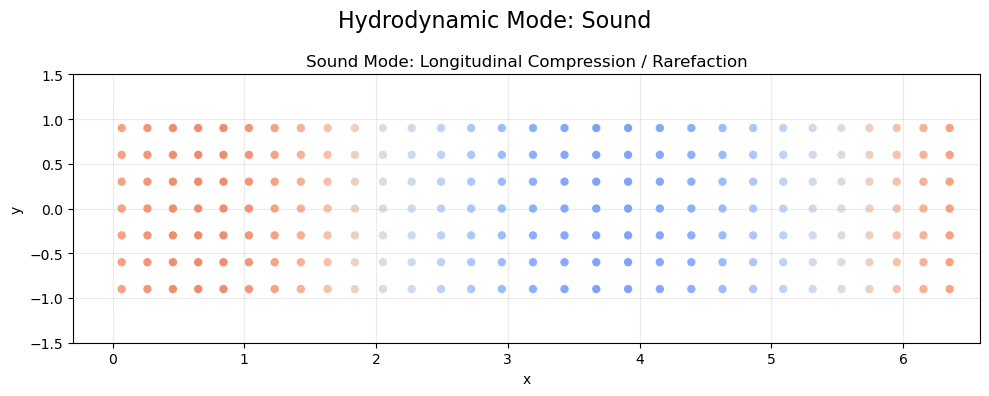

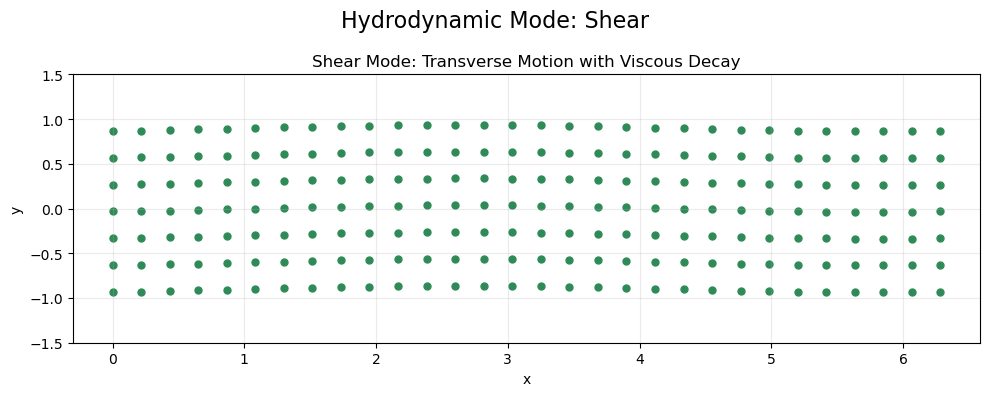

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

# ============================================================
# Parameters
# ============================================================
Lx = 2 * np.pi
Nx = 30
Ny = 7

x0 = np.linspace(0, Lx, Nx)
y0 = np.linspace(-0.9, 0.9, Ny)
X0, Y0 = np.meshgrid(x0, y0)

A_sound = 0.18
A_shear = 0.22

k_sound = 1.0
k_shear = 1.0

cs = 1.2
omega_sound = cs * k_sound

nu = 0.12
gamma_shear = nu * k_shear**2
gamma_sound = 0.03

omega_shear = 0.6   # set 0.0 for purely diffusive shear

fps = 25
T = 10
nframes = fps * T
dt = 0.06

# ============================================================
# Physics
# ============================================================
def sound_mode(t):
    phase = k_sound * X0 - omega_sound * t
    decay = np.exp(-gamma_sound * t)

    xi_x = A_sound * decay * np.cos(phase)
    X = X0 + xi_x
    Y = Y0

    drho = k_sound * A_sound * decay * np.sin(phase)
    return X, Y, drho


def shear_mode(t):
    phase = k_shear * X0 - omega_shear * t
    decay = np.exp(-gamma_shear * t)

    xi_y = A_shear * decay * np.cos(phase)
    X = X0
    Y = Y0 + xi_y
    return X, Y


# ============================================================
# Figure 1: Sound mode
# ============================================================
fig1, ax1 = plt.subplots(figsize=(10, 4))
fig1.suptitle("Hydrodynamic Mode: Sound", fontsize=16)

ax1.set_xlim(-0.3, Lx + 0.3)
ax1.set_ylim(-1.5, 1.5)
ax1.grid(alpha=0.25)
ax1.set_title("Sound Mode: Longitudinal Compression / Rarefaction")
ax1.set_xlabel("x")
ax1.set_ylabel("y")

sound_scatter = ax1.scatter([], [], s=25, c=[], cmap="coolwarm", vmin=-0.2, vmax=0.2)

def init_sound():
    Xs, Ys, drho = sound_mode(0)
    sound_scatter.set_offsets(np.column_stack([Xs.ravel(), Ys.ravel()]))
    sound_scatter.set_array(drho.ravel())
    return (sound_scatter,)

def update_sound(frame):
    t = frame * dt
    Xs, Ys, drho = sound_mode(t)
    sound_scatter.set_offsets(np.column_stack([Xs.ravel(), Ys.ravel()]))
    sound_scatter.set_array(drho.ravel())
    return (sound_scatter,)

anim_sound = FuncAnimation(
    fig1, update_sound, init_func=init_sound,
    frames=nframes, interval=1000/fps, blit=False
)

plt.tight_layout()
anim_sound.save("sound_mode.gif", writer=PillowWriter(fps=fps))
print("Saved animation to sound_mode.gif")


# ============================================================
# Figure 2: Shear mode
# ============================================================
fig2, ax2 = plt.subplots(figsize=(10, 4))
fig2.suptitle("Hydrodynamic Mode: Shear", fontsize=16)

ax2.set_xlim(-0.3, Lx + 0.3)
ax2.set_ylim(-1.5, 1.5)
ax2.grid(alpha=0.25)
ax2.set_title("Shear Mode: Transverse Motion with Viscous Decay")
ax2.set_xlabel("x")
ax2.set_ylabel("y")

shear_scatter = ax2.scatter([], [], s=25, color="seagreen")

def init_shear():
    Xh, Yh = shear_mode(0)
    shear_scatter.set_offsets(np.column_stack([Xh.ravel(), Yh.ravel()]))
    return (shear_scatter,)

def update_shear(frame):
    t = frame * dt
    Xh, Yh = shear_mode(t)
    shear_scatter.set_offsets(np.column_stack([Xh.ravel(), Yh.ravel()]))
    return (shear_scatter,)

anim_shear = FuncAnimation(
    fig2, update_shear, init_func=init_shear,
    frames=nframes, interval=1000/fps, blit=False
)

plt.tight_layout()
anim_shear.save("shear_mode.gif", writer=PillowWriter(fps=fps))
print("Saved animation to shear_mode.gif")

plt.show()